In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from datasets import load_dataset

# **Load dataset**

Load the dair-ai/emotion dataset from Hugging Face. https://huggingface.co/datasets/dair-ai/emotion

In [4]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [9]:
df_train = pd.DataFrame(
    {
        'text': train_text,
        'label': [label_name[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        'text': test_text,
        'label': [label_name[i] for i in test_label]
    }
)

In [10]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [11]:
df_train.isna().sum()

,0
text,0
label,0


In [12]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    16000 non-null  object
 1   label   16000 non-null  object
dtypes: object(2)
memory usage: 250.1+ KB


In [13]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [14]:
label_name = emotion_dataset['train'].features['label'].names

In [15]:
label_name

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [8]:
for i in train_label:
  print(label_name[i])

Streaming output truncated to the last 5000 lines.
sadness
sadness
anger
fear
love
joy
anger
sadness
sadness
joy
fear
joy
fear
love
love
anger
anger
sadness
fear
sadness
sadness
surprise
love
joy
joy
love
sadness
joy
joy
fear
sadness
anger
anger
sadness
love
fear
fear
anger
anger
joy
sadness
sadness
joy
joy
fear
sadness
joy
love
fear
anger
sadness
joy
anger
surprise
fear
joy
joy
love
fear
sadness
joy
anger
fear
anger
sadness
sadness
sadness
anger
sadness
fear
joy
anger
anger
sadness
fear
joy
anger
fear
sadness
joy
fear
joy
love
anger
fear
fear
fear
fear
joy
anger
anger
sadness
joy
sadness
joy
sadness
sadness
joy
sadness
fear
fear
joy
sadness
joy
sadness
joy
fear
anger
sadness
joy
anger
joy
joy
sadness
joy
joy
anger
anger
joy
joy
joy
sadness
joy
joy
joy
anger
anger
joy
love
joy
love
joy
joy
joy
sadness
joy
sadness
surprise
sadness
anger
anger
anger
fear
fear
joy
fear
fear
joy
anger
joy
joy
joy
love
joy
fear
sadness
sadness
surprise
sadness
sadness
anger
joy
love
fear
joy
anger
joy
surpr

# **Exploratory Data Analysis (EDA)**

<Axes: xlabel='label', ylabel='count'>

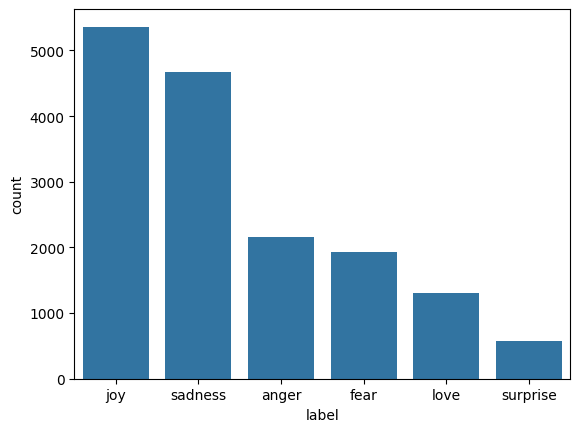

In [17]:
sns.countplot(x='label', data=df_train , order = df_train['label'].value_counts().index)

# Data Preprocessing - Using **NLP**

In [18]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000

tokenizer = Tokenizer(num_words = max_words, oov_token = '<uuk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
#print(train_sequence)
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(train_sequence, maxlen = 50, padding ='post', truncating = 'post')
padded_test_sequence = pad_sequences(test_sequence, maxlen = 50, padding ='post', truncating = 'post')

train_label = np.array(train_label)
test_label = np.array(test_label)

num_classes = len(np.unique(train_label))
num_classes


6

In [19]:

from sklearn.utils import class_weight


class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes      = np.unique(train_label),
    y            = train_label
)

class_weight_dict = dict(enumerate(class_weights))

In [20]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)


In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN , Embedding, LSTM, Dense, Dropout, GRU

rnn_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128, input_length=50),
    SimpleRNN(units = 128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units = 64),
    Dropout(0.5),
    Dense(units = num_classes, activation = 'softmax')# Output layer

])

rnn_model.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

In [22]:
rnn_model.fit(
    padded_train_sequence,
    train_label,
    validation_data = (padded_test_sequence, test_label),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]

)

rnn_loss , rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_label)
print(f'RNN Loss: {rnn_loss}')
print(f'RNN Accuracy: {rnn_accuracy}')

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.1596 - loss: 2.0455 - val_accuracy: 0.1800 - val_loss: 1.7795
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1388 - loss: 1.8992 - val_accuracy: 0.0955 - val_loss: 1.8356
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.1254 - loss: 1.8337 - val_accuracy: 0.1340 - val_loss: 1.7723
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1234 - loss: 1.8090 - val_accuracy: 0.2730 - val_loss: 1.7760
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.1371 - loss: 1.8029 - val_accuracy: 0.0475 - val_loss: 1.8151
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.1429 - loss: 1.7995 - val_accuracy: 0.0455 - val_loss: 1.7868
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1340 - loss: 1.7723
RNN Loss: 1.7723031044006348
RNN Accuracy: 0.1340000033378601


In [23]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence,
    train_label,
    validation_data=(padded_test_sequence, test_label),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_label)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.1509 - loss: 1.7950 - val_accuracy: 0.0795 - val_loss: 1.7905
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.1536 - loss: 1.7932 - val_accuracy: 0.1125 - val_loss: 1.7795
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.1632 - loss: 1.7897 - val_accuracy: 0.1050 - val_loss: 1.7965
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.0795 - loss: 1.7905
LSTM Loss: 1.7904865741729736
LSTM Accuracy: 0.0794999971985817


In [25]:
GRU_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128, input_length = 50),
    GRU(units = 128, return_sequences=True),
    Dropout(0.5),
    GRU(units = 64),
    Dropout(0.5),
    Dense(units = num_classes, activation = 'softmax')
])

GRU_model.compile(
    optimizer = 'adam',
    loss='sparse_categorical_crossentropy',
    metrics = ['accuracy']

)

GRU_model.fit(
    padded_train_sequence,
    train_label,
    validation_data = (padded_test_sequence, test_label),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

gru_loss, gru_accuracy = GRU_model.evaluate(padded_test_sequence, test_label)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.1618 - loss: 1.7967 - val_accuracy: 0.1120 - val_loss: 1.8198
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.1637 - loss: 1.7944 - val_accuracy: 0.0330 - val_loss: 1.8202
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.1581 - loss: 1.7949 - val_accuracy: 0.0805 - val_loss: 1.8144
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1120 - loss: 1.8198
GRU Loss: 1.8197702169418335
GRU Accuracy: 0.1120000034570694


In [28]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy],
}).sort_values(by = 'Test Accuracy', ascending = False)

result_df

,Model,Test Loss,Test Accuracy
0,RNN,1.772303,0.1340
2,GRU,1.819770,0.1120
1,LSTM,1.790487,0.0795


In [30]:
from tensorflow.keras.layers import Bidirectional

In [31]:
model_BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300, input_length = 50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

model_BiGRU.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

model_BiGRU.fit(
    padded_train_sequence,
    train_label,
    validation_data = (padded_test_sequence, test_label),
    epochs = 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)



Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.5842 - loss: 0.9979 - val_accuracy: 0.8785 - val_loss: 0.3964
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9082 - loss: 0.2569 - val_accuracy: 0.9080 - val_loss: 0.2282
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.9391 - loss: 0.1561 - val_accuracy: 0.9215 - val_loss: 0.2826
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9560 - loss: 0.1197 - val_accuracy: 0.9165 - val_loss: 0.2757
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9659 - loss: 0.0906 - val_accuracy: 0.9240 - val_loss: 0.2446


In [33]:
BiGRU_loss, BiGRU_accuracy = model_BiGRU.evaluate(padded_test_sequence, test_label)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9080 - loss: 0.2282
BiGRU Loss: 0.2282077968120575
BiGRU Accuracy: 0.9079999923706055


In [60]:
model_BiGRU.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (32, 50, 300)          │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (32, 50, 256)          │       330,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (32, 50, 256)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (32, 128)              │       123,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (32, 128)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (32, 6)                │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,363,988 (39.54 MB)

 Trainable params: 3,454,662 (13.18 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,909,326 (26.36 MB)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


<Axes: >

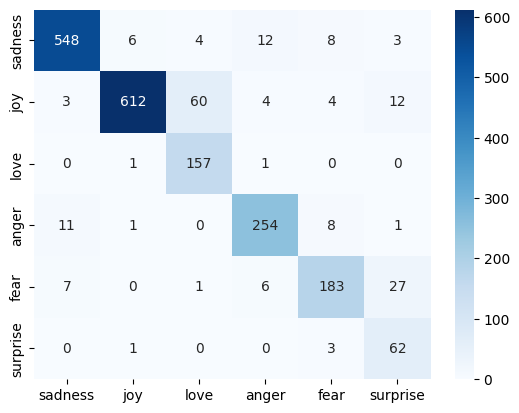

In [40]:
from sklearn.metrics import confusion_matrix

BiGRU_prediction = np.argmax(model_BiGRU.predict(padded_test_sequence), axis =1)

sns.heatmap(confusion_matrix(test_label,BiGRU_prediction), annot = True, cmap = 'Blues',fmt = 'd',xticklabels=label_name, yticklabels=label_name)

In [42]:
model_BiLSTM = Sequential([
    Embedding(input_dim = max_words, output_dim =300 , input_length = 50),
    Bidirectional(LSTM(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(LSTM(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

model_BiLSTM.compile(
    optimizer = 'adam',
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

model_BiLSTM.fit(
    padded_train_sequence,
    train_label,
    validation_data=(padded_test_sequence, test_label),
    epochs= 20,
    batch_size = 32,
    class_weight = class_weight_dict,
    callbacks = [early_stopping]
)

BiLSTM_loss, BiLSTM_accuracy = model_BiLSTM.evaluate(padded_test_sequence, test_label)
print(f"BiLSTM Loss : {BiLSTM_loss}")
print(f"BiLSTM Accuracy : {BiLSTM_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.5788 - loss: 1.0561 - val_accuracy: 0.8940 - val_loss: 0.3537
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9169 - loss: 0.2671 - val_accuracy: 0.9045 - val_loss: 0.2851
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9407 - loss: 0.1695 - val_accuracy: 0.9155 - val_loss: 0.2487
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8940 - loss: 0.3537
BiLSTM Loss : 0.3537119925022125
BiLSTM Accuracy : 0.8939999938011169


In [61]:
model_BiLSTM.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (32, 50, 300)          │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (32, 50, 256)          │       439,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (32, 50, 256)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (32, 128)              │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (32, 128)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (32, 6)                │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,813,268 (41.25 MB)

 Trainable params: 3,604,422 (13.75 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,208,846 (27.50 MB)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


<Axes: >

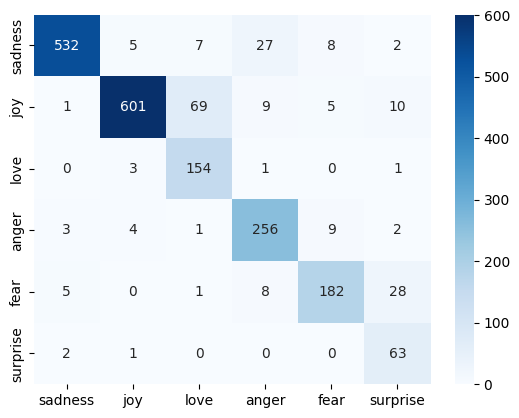

In [45]:
from sklearn.metrics import confusion_matrix

BiLSTM_prediction = np.argmax(model_BiLSTM.predict(padded_test_sequence),axis=1)

sns.heatmap(confusion_matrix(test_label, BiLSTM_prediction), annot=True, fmt='d',cmap='Blues',xticklabels=label_name, yticklabels=label_name)


In [52]:
sample_texts = [
    "I felt heartbroken when my favorite place was closed forever.",              # Sadness

    "The surprise party made me smile for the entire evening!",                   # Joy

    "I was shocked when I suddenly found my lost phone under the sofa.",         # Surprise

    "Walking through the empty house at night made me feel extremely scared.",    # Fear

    "I was furious when someone took credit for my hard work.",                   # Anger

    "I felt lonely after my best friend moved far away.",                        # Sadness

    "Spending the weekend with my family made me feel truly wonderful.",           # Joy

    "I was amazed when I received an unexpected award at the event.",             # Surprise

    "I became nervous when I heard strange sounds coming from outside.",           # Fear

    "I got extremely angry when my important files were deleted accidentally."    # Anger
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(model_BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_name[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
Text: I felt heartbroken when my favorite place was closed forever.
Predicted Emotion: sadness
Text: The surprise party made me smile for the entire evening!
Predicted Emotion: sadness
Text: I was shocked when I suddenly found my lost phone under the sofa.
Predicted Emotion: surprise
Text: Walking through the empty house at night made me feel extremely scared.
Predicted Emotion: fear
Text: I was furious when someone took credit for my hard work.
Predicted Emotion: anger
Text: I felt lonely after my best friend moved far away.
Predicted Emotion: sadness
Text: Spending the weekend with my family made me feel truly wonderful.
Predicted Emotion: joy
Text: I was amazed when I received an unexpected award at the event.
Predicted Emotion: surprise
Text: I became nervous when I heard strange sounds coming from outside.
Predicted Emotion: fear
Text: I got extremely angry when my important files were deleted accidentally.
Predicted Emotion: anger


In [56]:
sample_texts = [
    "I felt heartbroken when my favorite place was closed forever.",              # Sadness

    "The surprise party made me smile for the entire evening!",                   # Joy

    "I was shocked when I suddenly found my lost phone under the sofa.",         # Surprise

    "Walking through the empty house at night made me feel extremely scared.",    # Fear

    "I was furious when someone took credit for my hard work.",                   # Anger

    "I felt lonely after my best friend moved far away.",                        # Sadness

    "Spending the weekend with my family made me feel truly wonderful.",           # Joy

    "I was amazed when I received an unexpected award at the event.",             # Surprise

    "I became nervous when I heard strange sounds coming from outside.",           # Fear

    "I got extremely angry when my important files were deleted accidentally."    # Anger
]
sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(model_BiLSTM.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_name[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Text: I felt heartbroken when my favorite place was closed forever.
Predicted Emotion: sadness
Text: The surprise party made me smile for the entire evening!
Predicted Emotion: anger
Text: I was shocked when I suddenly found my lost phone under the sofa.
Predicted Emotion: surprise
Text: Walking through the empty house at night made me feel extremely scared.
Predicted Emotion: fear
Text: I was furious when someone took credit for my hard work.
Predicted Emotion: anger
Text: I felt lonely after my best friend moved far away.
Predicted Emotion: sadness
Text: Spending the weekend with my family made me feel truly wonderful.
Predicted Emotion: joy
Text: I was amazed when I received an unexpected award at the event.
Predicted Emotion: surprise
Text: I became nervous when I heard strange sounds coming from outside.
Predicted Emotion: surprise
Text: I got extremely angry when my important files were deleted accidentally.
Predicted Emotion: anger


In [ ]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True) 

#Save our BiGRU Model
model_BiGRU.save(os.path.join(model_dir, 'BiGRU_Modle.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)